# Milestone 2 — Phân tích LaTeX, chuẩn hóa và khử trùng

**CSC14119 — Nhập môn Khoa học Dữ liệu · Nhóm 3**

[![Mở trên Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DuyNhat1705/Intro2DS-Group3-Source/blob/main/src/parser.ipynb)

Notebook chạy pipeline trong `parsing.md`: **gom file → làm sạch → dựng cây và trích tài liệu tham khảo → hợp nhất bibliography → đổi khóa citation → khử trùng element → xuất bảng và thống kê**.

Đầu vào là corpus Milestone 1 đã có; notebook không tải lại arXiv. Chỉnh ô cấu hình rồi chọn **Run all**. Mặc định chạy thử 20 ID đầu của R1; đặt `SAMPLE_N = None` để chạy toàn bộ phạm vi. SaT chạy CPU và tải trọng số ở lần tách câu đầu tiên nếu máy chưa có cache.

In [1]:
# CẤU HÌNH — chỉnh trước khi Run all
from pathlib import Path

RANGES = {
    1: ("2609", 27834, 32833),
    2: ("2609", 17834, 22833),
    3: ("2608", 14007, 19006),
    4: ("2608", 4007, 9006),
    5: ("2511", 6709, 11708),
}
RUN_RANGES = "all"          # [3], [1, 2], "all" hoặc "local" (tìm bài từ thư mục/state)
SAMPLE_N = 5             # số ID đầu mỗi range; None = toàn bộ; local: giới hạn tổng số bài
WORKER = None             # None: tự đặt theo range; dùng tên khác nhau nếu chạy đồng thời

REPO_DIR = None           # local: tự tìm repo từ thư mục hiện tại; hoặc đường dẫn tuyệt đối
REPO_URL = "https://github.com/DuyNhat1705/Intro2DS-Group3-Source.git"
BRANCH = "main"           # Colab clone nhánh đã có các module parser
INSTALL_DEPENDENCIES = None  # None: tự cài trên Colab, chỉ kiểm tra trên local
MOUNT_DRIVE = True
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/Intro2DS-Group3"
DATA_DIR_OVERRIDE = None     # ví dụ r"C:/Intro2DS-Group3-Source/data"
OUTPUT_DIR_OVERRIDE = None   # mặc định statistics_data/parser, tách khỏi output scraper
SOURCE_STATE_PATHS = None    # None: tự đọc data/source_state.json và data/.state/**/source_state.json

RUN_SMOKE_TEST = True
RUN_PIPELINE = True
RESUME = True               # chỉ dùng lại checkpoint ok/empty khi nguồn, mã và tùy chọn không đổi
ENABLE_ENRICHMENT = False   # mặc định offline; True cho phép CrossRef và LLM nếu đã có key
FUZZY_THRESHOLD = 0.92
NUM_WORKERS = "auto"        # tự chọn theo CPU/RAM; 1 = tuần tự; số nguyên = giới hạn mong muốn
MAX_WORKERS = None          # giới hạn thêm số tiến trình; None = dùng giới hạn CPU
ADAPTIVE_RAM = True         # tự điều chỉnh lượng công việc và thu hồi worker rảnh khi thiếu RAM
RESERVE_RAM_GB = None       # None: tự chừa RAM cho hệ thống; hoặc số GiB muốn chừa
RAM_PER_WORKER_GB = 1.5     # mức dự trù tối thiểu mỗi worker, sẽ tăng theo RSS đo được
RAM_WAIT_TIMEOUT_SEC = 60   # hết thời gian chờ RAM thì lưu phần đã xong, để phần còn lại chạy tiếp sau
MAX_RUN_HOURS = 11.0        # kiểm tra giữa các bài; None = không giới hạn
MONITOR_EVERY_SEC = 1.0
DISK_EVERY_PAPERS = 100
REPORT_ALL_WORKERS = False  # ghép số liệu các worker sau khi đã gom output về cùng thư mục

## 1. Cách chạy trên local và Google Colab

**Local:** dùng Python 3.12 trở lên, cài `pip install -r src/requirements.txt`, mở notebook từ repo hoặc đặt `REPO_DIR`. Dữ liệu mặc định ở `<repo>/data`. Muốn xử lý thư mục tự chọn, đặt `DATA_DIR_OVERRIDE` và `RUN_RANGES = "local"`.

**Colab:** chọn runtime CPU. Notebook clone repo nếu chưa có, cài các thư viện parser theo phiên bản của `src/requirements.txt`, rồi mount Drive. Cần đẩy mã parser lên nhánh `BRANCH` trước khi mở ở Colab. Nếu repo đã tồn tại, notebook dùng mã hiện có và không tự pull đè thay đổi. Mặc định đọc `MyDrive/Intro2DS-Group3/data` và ghi `MyDrive/Intro2DS-Group3/statistics_data/parser`.

**Sau khi cập nhật mã:** restart kernel/runtime rồi Run all để nạp đúng module mới. Không cần xóa kết quả cũ; chữ ký mã thay đổi sẽ tự làm mất hiệu lực checkpoint cũ. Chỉ bấm Run all trong kernel đang giữ module cũ sẽ không tự nạp lại mã Python.

**Chạy tiếp:** mỗi bài hoàn thành có phân mảnh Parquet và checkpoint riêng. Khi chạy lại, nguồn, cấu hình và tính toàn vẹn các tệp đầu ra được kiểm tra bằng SHA-256; bài `partial/error` được thử lại. Không chạy hai notebook có cùng `WORKER` vào một thư mục output. Có thể dừng bằng Interrupt; bài đang làm chưa hoàn thành sẽ được chạy lại ở phiên sau. Giới hạn giờ chỉ được kiểm tra giữa các bài.

**Song song:** mặc định `NUM_WORKERS="auto"`. Mỗi tiến trình xử lý trọn một bài và tái sử dụng mô hình SaT riêng. Bộ điều phối chạy một bài để đo RAM trước khi tăng số worker, giới hạn theo CPU và RAM khả dụng. Có thể đặt `MAX_WORKERS` để giới hạn thêm, hoặc `NUM_WORKERS=1` để trở lại chế độ tuần tự. Trên Windows/Colab, worker dùng cơ chế spawn từ module Python, không chạy lại các ô notebook.

**Mạng:** `ENABLE_ENRICHMENT=False` tắt enrichment; lần đầu tải trọng số SaT và cài thư viện vẫn cần mạng. Để chạy hoàn toàn offline, cài sẵn thư viện và cache trọng số trước. API key Gemini, nếu dùng, lấy từ biến môi trường hoặc tự nạp vào môi trường từ Colab Secrets; notebook không ghi key vào cấu hình/log.

In [2]:
import importlib.metadata
import os
import subprocess
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if REPO_DIR is not None:
    REPO_ROOT = Path(REPO_DIR).expanduser().resolve()
elif IN_COLAB:
    REPO_ROOT = Path("/content/Intro2DS-Group3-Source")
    if not REPO_ROOT.exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(REPO_ROOT)], check=True)
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    REPO_ROOT = next((p for p in candidates if (p / "src" / "hierarchy.py").is_file()), None)
    if REPO_ROOT is None:
        raise FileNotFoundError("Không tìm thấy repo. Hãy đặt REPO_DIR ở ô cấu hình.")

required_files = ["parser_pipeline.py", "parser_reporting.py", "parser_parallel.py", "gather_clean_tex.py", "bibtex.py", "hierarchy.py"]
missing_files = [name for name in required_files if not (REPO_ROOT / "src" / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Nhánh đang dùng thiếu module {missing_files}; cập nhật mã parser trước khi chạy.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

parser_packages = {"pandas", "pyarrow", "matplotlib", "bibtexparser", "psutil", "wtpsplit", "onnxruntime"}
requirements = [line.strip() for line in (REPO_ROOT / "src" / "requirements.txt").read_text().splitlines()
                if line.strip().split("==")[0] in parser_packages]
if {r.split("==")[0] for r in requirements} != parser_packages:
    raise ValueError("requirements.txt chưa định nghĩa đủ các thư viện parser.")
install = IN_COLAB if INSTALL_DEPENDENCIES is None else INSTALL_DEPENDENCIES
versions_before = {name: getattr(sys.modules.get(name), "__version__", None) for name in parser_packages}
if install:
    subprocess.run([sys.executable, "-m", "pip", "install", *requirements], check=True)

dependency_rows = []
for requirement in requirements:
    name, expected = requirement.split("==")
    try:
        actual = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        raise RuntimeError(f"Thiếu {name}. Chạy pip install -r src/requirements.txt rồi khởi động lại kernel.")
    dependency_rows.append({"thư viện": name, "yêu cầu": expected, "đã cài": actual})
    if versions_before[name] is not None and versions_before[name] != actual:
        raise RuntimeError(f"{name} đã được nạp trước khi cập nhật. Restart kernel/runtime rồi Run all lại.")
    if actual != expected:
        print(f"Lưu ý: {name}={actual}, khác bản tái lập {expected}.")
print("Môi trường:", "Google Colab CPU" if IN_COLAB else "Local", "| Repo:", REPO_ROOT)

Môi trường: Local | Repo: /mnt/c/Intro2DS-Group3-Source


In [3]:
if IN_COLAB and MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

project_root = Path(DRIVE_PROJECT_DIR) if IN_COLAB and MOUNT_DRIVE else REPO_ROOT
DATA_DIR = Path(DATA_DIR_OVERRIDE).expanduser().resolve() if DATA_DIR_OVERRIDE else project_root / "data"
OUTPUT_DIR = Path(OUTPUT_DIR_OVERRIDE).expanduser().resolve() if OUTPUT_DIR_OVERRIDE else project_root / "statistics_data" / "parser"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Không có thư mục dữ liệu {DATA_DIR}. Kiểm tra Drive hoặc DATA_DIR_OVERRIDE.")
if OUTPUT_DIR.resolve() == DATA_DIR.resolve():
    raise ValueError("OUTPUT_DIR phải khác DATA_DIR để tách output parser khỏi nguồn scraper.")

import json
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
from src.parser_pipeline import discover_publications, parse_publication
from src.parser_reporting import run_parser

display(pd.DataFrame(dependency_rows))
print("Nguồn:", DATA_DIR)
print("Đầu ra:", OUTPUT_DIR)

,thư viện,yêu cầu,đã cài
0,bibtexparser,1.4.3,1.4.3
1,psutil,7.2.2,7.2.2
2,pandas,3.1.0,3.1.0
3,pyarrow,26.0.0,26.0.0
4,matplotlib,3.11.2,3.11.2
5,wtpsplit,2.2.2,2.2.2
6,onnxruntime,1.31.1,1.31.1


Nguồn: /mnt/c/Intro2DS-Group3-Source/data
Đầu ra: /mnt/c/Intro2DS-Group3-Source/statistics_data/parser


## 2. Chọn phạm vi và kiểm tra đầu vào

Range giữ nguyên định nghĩa trong `scraper.ipynb`. Mẫu thử chỉ thay đổi phạm vi báo cáo, không được suy diễn thành toàn bộ 25.000 ID. Chế độ `local` tìm bài qua thư mục và state đã có, kể cả bản rỗng chỉ còn state; chế độ range giữ cả ID chưa có dữ liệu để mẫu số độ phủ không bị thu nhỏ.

Danh sách phiên bản lấy từ metadata, state Milestone 1 và thư mục thực tế. Phiên bản đã xác nhận `no_tex` được ghi `empty`; thiếu thư mục không có bằng chứng không được tự coi là rỗng. ID chưa có bất kỳ thông tin phiên bản dùng bản ghi v1 để biểu diễn thiếu đầu vào, không phải bằng chứng bài có một phiên bản. Lỗi metadata, nguồn thiếu và bibliography mơ hồ được giữ trong kết quả kiểm tra/trạng thái.

In [4]:
if SAMPLE_N is not None and (type(SAMPLE_N) is not int or SAMPLE_N <= 0):
    raise ValueError("SAMPLE_N phải là số nguyên dương hoặc None.")
if RUN_RANGES == "local":
    selected_ranges = []
    jobs = discover_publications(DATA_DIR, source_state_paths=SOURCE_STATE_PATHS)
    if SAMPLE_N is not None:
        jobs = jobs[:SAMPLE_N]
else:
    selected_ranges = sorted(RANGES) if RUN_RANGES == "all" else list(RUN_RANGES)
    if not selected_ranges or len(set(selected_ranges)) != len(selected_ranges) or any(r not in RANGES for r in selected_ranges):
        raise ValueError("RUN_RANGES phải là danh sách range hợp lệ, 'all' hoặc 'local'.")
    targets = []
    for r in selected_ranges:
        month, first, last = RANGES[r]
        end = last + 1 if SAMPLE_N is None else min(last + 1, first + SAMPLE_N)
        targets.extend(f"{month}.{number:05d}" for number in range(first, end))
    if len(targets) != len(set(targets)):
        raise ValueError("Định nghĩa các range đang chồng lấn.")
    jobs = discover_publications(DATA_DIR, target_ids=targets, source_state_paths=SOURCE_STATE_PATHS)

def range_label(arxiv_id):
    for r, (month, first, last) in RANGES.items():
        if arxiv_id.startswith(month + ".") and arxiv_id.split(".")[-1].isdigit() and first <= int(arxiv_id.split(".")[-1]) <= last:
            return f"R{r}"
    return "local"

for job in jobs:
    job["range"] = range_label(job["arxiv_id"])
WORKER_NAME = WORKER or ("local" if RUN_RANGES == "local" else "+".join(f"R{r}" for r in selected_ranges))
print(f"Worker: {WORKER_NAME} | {len(jobs):,} ID | {sum(len(j['version_dirs']) for j in jobs):,} phiên bản dự kiến")
preview = [{"arxiv_id": j["arxiv_id"], "range": j["range"], "số phiên bản": len(j["version_dirs"]),
            "thư mục": str(j.get("paper_dir") or "chưa có"), "lỗi phát hiện": "; ".join(j.get("discovery_errors", []))}
           for j in jobs[:20]]
display(pd.DataFrame(preview))

Worker: R1+R2+R3+R4+R5 | 25 ID | 28 phiên bản dự kiến


,arxiv_id,range,số phiên bản,thư mục,lỗi phát hiện
0,2511.06709,R5,1,/mnt/c/Intro2DS-Group3-Source/data/2511-06709,
1,2511.06710,R5,1,/mnt/c/Intro2DS-Group3-Source/data/2511-06710,
2,2511.06711,R5,1,/mnt/c/Intro2DS-Group3-Source/data/2511-06711,
3,2511.06712,R5,1,/mnt/c/Intro2DS-Group3-Source/data/2511-06712,
4,2511.06713,R5,2,/mnt/c/Intro2DS-Group3-Source/data/2511-06713,
5,2608.04007,R4,1,/mnt/c/Intro2DS-Group3-Source/data/2608-04007,
6,2608.04008,R4,1,/mnt/c/Intro2DS-Group3-Source/data/2608-04008,
7,2608.04009,R4,2,/mnt/c/Intro2DS-Group3-Source/data/2608-04009,
8,2608.04010,R4,1,/mnt/c/Intro2DS-Group3-Source/data/2608-04010,
9,2608.04011,R4,1,/mnt/c/Intro2DS-Group3-Source/data/2608-04011,


## 3. Kiểm thử nhỏ trước khi chạy corpus

Fixture offline gồm hai phiên bản có cùng câu nhưng khác heading/khóa citation và một phiên bản không có TeX. Kiểm tra bibliography giữ cả năm lẫn DOI và câu dùng chung vẫn gắn đúng cha. Phần này giả lập kết quả mô hình tách câu để kiểm tra tích hợp; không đánh giá độ chính xác SaT.

In [5]:
if RUN_SMOKE_TEST:
    from tempfile import TemporaryDirectory
    from unittest.mock import patch
    with TemporaryDirectory() as temporary:
        base = Path(temporary)
        paper = base / "2301-00001"
        paper.mkdir()
        (paper / "metadata.json").write_text(json.dumps({"arxiv_id": "2301.00001", "num_versions": 3}), encoding="utf-8")
        for version, title, key, fields in [(1, "Introduction", "old", "year={2017}"),
                                           (2, "Background", "new", "doi={10.1000/attention}")]:
            folder = paper / f"v{version}"
            folder.mkdir()
            (folder / "main.tex").write_text(r"\documentclass{article}\begin{document}" +
                rf"\section{{{title}}}We study attention \cite{{{key}}}.\bibliography{{refs}}" +
                r"\end{document}", encoding="utf-8")
            (folder / "refs.bib").write_text(f"@article{{{key},title={{Attention Is All You Need}},"
                f"author={{Vaswani, Ashish}},{fields}}}", encoding="utf-8")
        (paper / "v3").mkdir()
        with patch("src.hierarchy._sentence_model") as model:
            model.return_value.split.side_effect = lambda text, **kwargs: [text]
            demo = parse_publication(discover_publications(base)[0], enrich=False)
        assert len(demo["bibtex"]) == 1 and demo["bibtex"][0]["year"] == 2017
        assert demo["bibtex"][0]["doi"] == "10.1000/attention"
        sentence = [r for r in demo["elements"] if r["kind"] == "sentence"]
        assert len(sentence) == 1
        edges = [r for r in demo["hierarchy"] if r["element_id"] == sentence[0]["element_id"]]
        assert len(edges) == 2 and edges[0]["parent_id"] != edges[1]["parent_id"]
        assert any(r["version"] == 3 and r["status"] == "empty" for r in demo["version_status"])
        print("Kiểm thử tích hợp đã đạt: hợp nhất reference, dùng chung câu, đúng cha theo phiên bản, giữ phiên bản rỗng.")

Kiểm thử tích hợp đã đạt: hợp nhất reference, dùng chung câu, đúng cha theo phiên bản, giữ phiên bản rỗng.


## 4. Chạy pipeline và lưu checkpoint

Các bài có thể chạy song song bằng nhiều tiến trình; mọi phiên bản của cùng bài vẫn được xử lý và hợp nhất trong cùng worker, giữ nguyên phương pháp parser. Worker tái sử dụng mô hình SaT CPU, còn tiến trình chính ghi Parquet/checkpoint và thống kê. Số bài đang chạy được giới hạn, không đẩy cả corpus vào hàng đợi. Bảng tổng được ghép theo batch và giữ thứ tự bài ổn định dù công việc hoàn thành khác thứ tự.

Khi `ADAPTIVE_RAM=True`, chương trình chừa RAM hệ thống, đo RSS của worker và cập nhật mức dự trù. Khi RAM giảm, chương trình ngừng cấp thêm bài và thu hồi tiến trình đang rảnh; bài đang chạy được hoàn tất. Nếu không còn bài đang chạy mà RAM vẫn không đủ sau `RAM_WAIT_TIMEOUT_SEC`, phiên lưu phần đã xong và báo lỗi để có thể chạy tiếp sau. Đây là cơ chế giảm nguy cơ hết RAM, không phải hạn mức RAM cứng: một bài quá lớn vẫn có thể vượt dự trù. `NUM_WORKERS=1` chạy trực tiếp tuần tự, không dùng bộ điều phối RAM.

Hết `MAX_RUN_HOURS` thì không cấp bài mới, nhưng chờ các bài đã cấp hoàn tất. Interrupt dọn các tiến trình do phiên tạo; bài chưa ghi checkpoint được đánh dấu pending. Lịch sử tăng/giảm worker và chờ RAM nằm trong `events.jsonl` và thông tin song song của phiên.

`paper_success` đúng nếu mọi phiên bản dự kiến được xử lý đầy đủ hoặc xác nhận rỗng. `ok` có thể đi kèm ghi chú (`notice`) về metadata đã hợp nhất hoặc quan hệ lặp đã được giữ nguyên; ghi chú này không làm bài bị parse lại. `review_required=True` cho biết chất lượng metadata/schema còn cần xem xét, tách biệt với việc pipeline đã hoàn tất.

`partial` dành cho kết quả còn thiếu hoặc chưa chắc đầy đủ: file nội dung chính không có, macro/conditional chưa giải được, LaTeX lỗi hoặc khóa citation mơ hồ. `error` là bước xử lý thất bại. Các trường hợp này tiếp tục được thử lại và không được tính thành công đầy đủ. Xem `issues.csv` để tìm việc cần khắc phục; `warnings.csv` giữ mọi chẩn đoán kèm `affects_status` và `requires_review`. Không thể tái tạo chính xác tài liệu tham khảo từ một `.bbl` đã bị thiếu bằng cách đổi nhãn trạng thái.

In [6]:
def show_progress(done, total, stats):
    if done == 1 or done % 25 == 0 or done == total:
        print(f"[{done:,}/{total:,}] {stats['arxiv_id']} — {stats['status']} | "
              f"element: {stats.get('elements_before', 0)} → {stats.get('elements_after', 0)} | "
              f"ghi chú: {stats.get('notice_count', 0)}, cảnh báo thiếu dữ liệu: {stats.get('blocking_warning_count', 0)}")
        if stats['status'] not in {'ok', 'empty'}:
            print("  Lý do:", stats.get('message', '')[:700])

if RUN_PIPELINE:
    result = run_parser(jobs, OUTPUT_DIR, worker=WORKER_NAME, ranges=RANGES,
        enrich=ENABLE_ENRICHMENT, fuzzy_threshold=FUZZY_THRESHOLD, resume=RESUME,
        max_run_hours=MAX_RUN_HOURS, monitor_interval=MONITOR_EVERY_SEC,
        disk_every=DISK_EVERY_PAPERS, progress=show_progress,
        num_workers=NUM_WORKERS, max_workers=MAX_WORKERS, adaptive_ram=ADAPTIVE_RAM,
        reserve_ram_gb=RESERVE_RAM_GB, ram_per_worker_gb=RAM_PER_WORKER_GB,
        ram_wait_timeout_sec=RAM_WAIT_TIMEOUT_SEC)
    summary = result["summary"]
else:
    summary_path = OUTPUT_DIR / "report_exports" / WORKER_NAME / "summary_stats.json"
    if not summary_path.exists():
        raise FileNotFoundError("Chưa có báo cáo. Đặt RUN_PIPELINE=True để chạy lần đầu.")
    summary = json.loads(summary_path.read_text(encoding="utf-8"))

REPORTS_DIR = OUTPUT_DIR / "report_exports" / WORKER_NAME
TABLES_DIR = OUTPUT_DIR / "tables" / WORKER_NAME
display(pd.DataFrame([{
    "ID trong phạm vi": summary["target_ids"], "bài thành công": summary["papers_success"],
    "tỷ lệ thành công": summary["success_rate"], "element sau khử trùng": summary["elements_after"],
    "reference sau khử trùng": summary["bibtex_after"], "dừng do": summary["run"]["stop_reason"],
    "thời gian phiên (giây)": summary["run"]["duration_sec"],
    "RAM RSS đỉnh (MiB)": summary["run"]["peak_rss_bytes"] / 2**20,
    "bảng Parquet (MiB)": summary["table_bytes"] / 2**20,
}]))
if summary["run"].get("parallel"):
    print("Điều phối CPU/RAM:", summary["run"]["parallel"])
if summary["run"]["stop_reason"] == "error":
    print("Phiên có lỗi:", summary["run"].get("error"), "— xem parser.log trước khi dùng bảng.")

[1/25] 2511.06709 — ok | element: 236 → 236 | ghi chú: 3, cảnh báo thiếu dữ liệu: 0
[25/25] 2609.27836 — ok | element: 3013 → 1772 | ghi chú: 132, cảnh báo thiếu dữ liệu: 0


,ID trong phạm vi,bài thành công,tỷ lệ thành công,element sau khử trùng,reference sau khử trùng,dừng do,thời gian phiên (giây),RAM RSS đỉnh (MiB),bảng Parquet (MiB)
0,25,23,0.92,10476,1381,completed,67.768726,4817.726562,0.815086


Điều phối CPU/RAM: {'event': 'parallel_summary', 'elapsed_sec': 64.93581714899983, 'workers': 0, 'active': 0, 'submitted': 25, 'completed': 25, 'total_jobs': 25, 'cpu_cap': 16, 'worker_cap': 16, 'adaptive_ram': True, 'reserve_ram_gb': 0.7636596679687501, 'ram_per_worker_gb': 1.5, 'previous_workers': 2, 'reason': 'exhausted', 'available_ram_gb': 4.759044647216797, 'memory_estimate_gb': 1.569140625, 'pending': 0, 'peak_workers': 4, 'peak_in_flight': 4, 'worker_errors': 0, 'ram_wait_sec': 0.0, 'stopped_reason': 'exhausted'}


## 5. Thống kê độ phủ, khử trùng và hiệu năng

Các CSV/JSON tương ứng hướng dẫn `statistics_data_output.md`, được điều chỉnh cho Milestone 2. `per_version.csv` bổ sung độ phủ phiên bản. `success_rate` dùng toàn bộ ID của phạm vi làm mẫu số; bản ghi `pending` do hết giờ hoặc Interrupt vẫn được giữ. Thời gian parse từ checkpoint khác chi phí của lần chạy hiện tại. Khi chạy song song, tổng thời gian xử lý từng bài có thể lớn hơn thời gian thực của phiên vì nhiều bài chạy cùng lúc; dùng duration_sec của phiên khi so sánh tốc độ.

RSS là tổng bộ nhớ cư trú của tiến trình Python và tiến trình con, không phải RAM của toàn máy. Đo theo chu kỳ có thể bỏ qua đỉnh rất ngắn; thời gian lần chạy đầu bao gồm tải mô hình trong bước parse. `output_snapshot` đo thư mục output tại thời điểm ghi nhận, gồm phân mảnh, bảng tổng và log. `table_bytes` chỉ đo ba bảng tổng để báo dung lượng dataset, tránh cộng đôi phân mảnh.

In [7]:
per_paper = pd.read_csv(REPORTS_DIR / "per_paper.csv", dtype={"arxiv_id": str})
per_version = pd.read_csv(REPORTS_DIR / "per_version.csv", dtype={"arxiv_id": str})
range_stats = pd.read_csv(REPORTS_DIR / "range_stats.csv")
display(range_stats)
display(per_paper.head(20))
display(per_version.head(20))
issues = per_paper[~per_paper["status"].isin(["ok", "empty"])]
print(f"Có {len(issues):,} bài còn thiếu/lỗi hoặc chưa chạy.")
display(issues.head(20))
diagnostics = pd.read_csv(REPORTS_DIR / "warnings.csv", dtype={"arxiv_id": str})
actionable_versions = pd.read_csv(REPORTS_DIR / "issues.csv", dtype={"arxiv_id": str})
print("Phiên bản cần khắc phục:")
display(actionable_versions.head(30))
print("Ghi chú chất lượng và cảnh báo (affects_status=True mới làm kết quả không đầy đủ):")
display(diagnostics.head(30))

,range,target_ids,papers_success,success_rate,versions_expected,versions_ok,versions_empty,versions_partial,versions_error,elements_before,elements_after,bibtex_before,bibtex_after,input_bytes,current_run_sec,mean_input_bytes,mean_bibtex_after,mean_elapsed_sec
0,R1,5,5,1.0,6.0,6.0,0.0,0.0,0.0,4987.0,3696.0,158.0,146.0,601887.0,47.825822,120377.4,29.2,9.285058
1,R2,5,4,0.8,5.0,4.0,0.0,1.0,0.0,2321.0,2271.0,116.0,114.0,456158.0,40.965687,91231.6,22.8,7.960021
2,R3,5,5,1.0,5.0,5.0,0.0,0.0,0.0,1554.0,1521.0,354.0,339.0,586819.0,31.614824,117363.8,67.8,6.066570
3,R4,5,4,0.8,6.0,3.0,1.0,2.0,0.0,1430.0,1150.0,863.0,670.0,643946.0,28.911376,128789.2,134.0,5.490508
4,R5,5,5,1.0,6.0,5.0,1.0,0.0,0.0,2329.0,1838.0,160.0,112.0,535350.0,54.246401,107070.0,22.4,10.582960


,arxiv_id,status,paper_success,versions_expected,versions_ok,versions_empty,versions_partial,versions_error,versions_not_found,versions_missing_dir,...,unify_publication_sec,unify_publication_status,rewrite_citations_sec,rewrite_citations_status,build_element_tables_sec,build_element_tables_status,output_table_bytes,range,reused,current_run_sec
0,2511.06709,ok,True,1,1,0,0,0,0,0,...,0.000040,ok,0.002528,ok,0.000535,ok,20275,R5,False,9.159799
1,2511.06710,ok,True,1,1,0,0,0,0,0,...,0.000036,ok,0.003096,ok,0.001292,ok,31752,R5,False,2.713970
2,2511.06711,ok,True,1,1,0,0,0,0,0,...,0.017037,ok,0.011569,ok,0.006056,ok,39688,R5,False,15.208984
3,2511.06712,empty,True,1,0,1,0,0,0,0,...,0.000045,ok,0.000006,ok,0.000009,ok,3485,R5,False,0.218022
4,2511.06713,ok,True,2,2,0,0,0,0,0,...,0.018496,ok,0.013540,ok,0.002886,ok,51801,R5,False,26.945626
5,2608.04007,ok,True,1,1,0,0,0,0,0,...,0.139034,ok,0.004198,ok,0.000966,ok,63259,R4,False,13.327659
6,2608.04008,ok,True,1,1,0,0,0,0,0,...,0.007227,ok,0.002052,ok,0.000716,ok,25278,R4,False,1.187431
7,2608.04009,partial,False,2,0,0,2,0,0,0,...,0.127754,ok,0.005767,ok,0.001343,ok,43294,R4,False,5.082355
8,2608.04010,ok,True,1,1,0,0,0,0,0,...,0.040068,ok,0.005337,ok,0.005394,ok,50790,R4,False,9.097021
9,2608.04011,empty,True,1,0,1,0,0,0,0,...,0.000109,ok,0.000007,ok,0.000009,ok,3485,R4,False,0.216911


,arxiv_id,version,status,message,missing_count,warning_count,source_status,bibliography_status,bibliography_missing,required_missing_count,blocking_warning_count,notice_count,review_required,missing,errors
0,2511.06709,1,ok,Đã xử lý phiên bản; 3 ghi chú (xem warnings.csv),1,3,NaN,missing_sources,['neurips_2025.bbl'],0,0,3,True,['neurips_2025.bbl'],[]
1,2511.06710,1,ok,Đã xử lý phiên bản; 15 ghi chú (xem warnings.csv),4,15,NaN,missing_sources,"['IEEEabrv.bib', 'StringDefinitions.bib', 'JCg...",0,0,15,True,"['IEEEabrv.bib', 'StringDefinitions.bib', 'JCg...",[]
2,2511.06711,1,ok,Đã xử lý phiên bản; 37 ghi chú (xem warnings.csv),0,37,NaN,ok,[],0,0,37,False,[],[]
3,2511.06712,1,empty,Thư mục phiên bản không có nguồn TeX,0,0,NaN,not_run,[],0,0,0,False,[],[]
4,2511.06713,1,ok,Đã xử lý phiên bản; 68 ghi chú (xem warnings.csv),0,68,NaN,ok,[],0,0,68,True,[],[]
5,2511.06713,2,ok,Đã xử lý phiên bản; 68 ghi chú (xem warnings.csv),0,68,NaN,ok,[],0,0,68,True,[],[]
6,2608.04007,1,ok,Đã xử lý phiên bản; 131 ghi chú (xem warnings....,0,131,NaN,ok,[],0,0,131,True,[],[]
7,2608.04008,1,ok,Đã xử lý phiên bản; 37 ghi chú (xem warnings.csv),0,37,NaN,ok,[],0,0,37,False,[],[]
8,2608.04009,1,partial,Cảnh báo: Ghi chú khi gom nguồn: 5 conditional...,0,47,NaN,ok,[],0,1,46,True,[],[]
9,2608.04009,2,partial,Cảnh báo: Ghi chú khi gom nguồn: 5 conditional...,0,47,NaN,ok,[],0,1,46,True,[],[]


Có 2 bài còn thiếu/lỗi hoặc chưa chạy.


,arxiv_id,status,paper_success,versions_expected,versions_ok,versions_empty,versions_partial,versions_error,versions_not_found,versions_missing_dir,...,unify_publication_sec,unify_publication_status,rewrite_citations_sec,rewrite_citations_status,build_element_tables_sec,build_element_tables_status,output_table_bytes,range,reused,current_run_sec
7,2608.04009,partial,False,2,0,0,2,0,0,0,...,0.127754,ok,0.005767,ok,0.001343,ok,43294,R4,False,5.082355
17,2609.17836,partial,False,1,0,0,1,0,0,0,...,0.013002,ok,0.015601,ok,0.001408,ok,43295,R2,False,7.078674


Phiên bản cần khắc phục:


,arxiv_id,version,status,message,missing_count,warning_count,source_status,bibliography_status,bibliography_missing,required_missing_count,blocking_warning_count,notice_count,review_required,missing,errors
0,2608.04009,1,partial,Cảnh báo: Ghi chú khi gom nguồn: 5 conditional...,0,47,NaN,ok,[],0,1,46,True,[],[]
1,2608.04009,2,partial,Cảnh báo: Ghi chú khi gom nguồn: 5 conditional...,0,47,NaN,ok,[],0,1,46,True,[],[]
2,2609.17836,1,partial,Cảnh báo: Unclosed inline math,0,12,NaN,ok,[],0,1,11,True,[],[]


Ghi chú chất lượng và cảnh báo (affects_status=True mới làm kết quả không đầy đủ):


,arxiv_id,version,stage,category,severity,affects_status,requires_review,message
0,2511.06709,1.0,gather,MissingBibliographyWarning,notice,False,True,Cảnh báo: /mnt/c/Intro2DS-Group3-Source/data/2...
1,2511.06709,1.0,gather,ParserWarning,notice,False,True,Cảnh báo: Bỏ qua bibliography không có nguồn: ...
2,2511.06709,1.0,gather,ParserWarning,notice,False,True,Cảnh báo: Ghi chú khi gom nguồn: include not f...
3,2511.06710,1.0,gather,MissingBibliographyWarning,notice,False,True,Cảnh báo: /mnt/c/Intro2DS-Group3-Source/data/2...
4,2511.06710,1.0,gather,MissingBibliographyWarning,notice,False,True,Cảnh báo: /mnt/c/Intro2DS-Group3-Source/data/2...
5,2511.06710,1.0,gather,MissingBibliographyWarning,notice,False,True,Cảnh báo: /mnt/c/Intro2DS-Group3-Source/data/2...
6,2511.06710,1.0,gather,MissingBibliographyWarning,notice,False,True,Cảnh báo: /mnt/c/Intro2DS-Group3-Source/data/2...
7,2511.06710,1.0,gather,ParserWarning,notice,False,True,Cảnh báo: Bỏ qua bibliography không có nguồn: ...
8,2511.06710,1.0,gather,ParserWarning,notice,False,True,Cảnh báo: Ghi chú khi gom nguồn: bibliography ...
9,2511.06710,1.0,gather,ParserWarning,notice,False,True,Cảnh báo: Ghi chú khi gom nguồn: bibliography ...


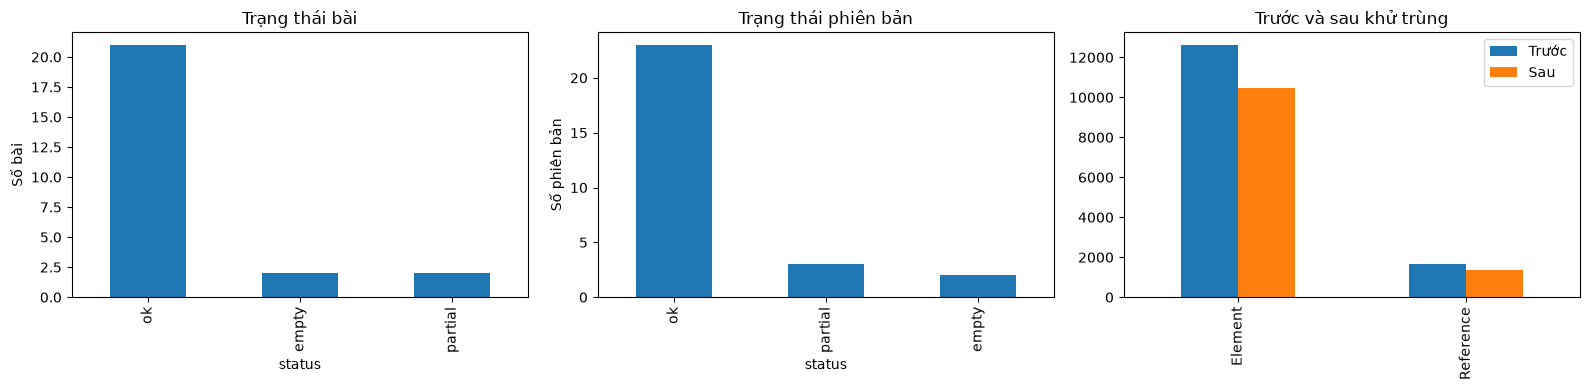

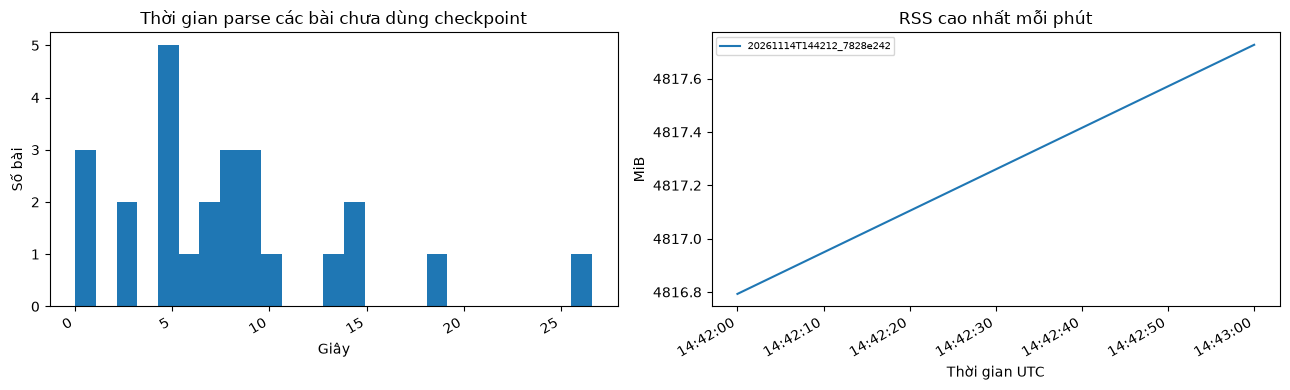

In [8]:
import matplotlib.pyplot as plt

FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
per_paper["status"].value_counts().plot.bar(ax=axes[0], title="Trạng thái bài") if len(per_paper) else axes[0].set_title("Chưa có bài")
axes[0].set_ylabel("Số bài")
if len(per_version):
    per_version["status"].value_counts().plot.bar(ax=axes[1], title="Trạng thái phiên bản")
else:
    axes[1].set_title("Chưa có phiên bản")
axes[1].set_ylabel("Số phiên bản")
pd.DataFrame({"Trước": [summary["elements_before"], summary["bibtex_before"]],
              "Sau": [summary["elements_after"], summary["bibtex_after"]]},
             index=["Element", "Reference"]).plot.bar(ax=axes[2], title="Trước và sau khử trùng")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "coverage_dedup.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
current = per_paper[per_paper["reused"].eq(False)]
times = pd.to_numeric(current["elapsed_sec"], errors="coerce").dropna()
if len(times):
    axes[0].hist(times, bins=min(30, max(1, len(times))))
axes[0].set(title="Thời gian parse các bài chưa dùng checkpoint", xlabel="Giây", ylabel="Số bài")
monitor_path = REPORTS_DIR / "monitor.csv"
if monitor_path.exists():
    monitor = pd.read_csv(monitor_path)
    for run_id, group in monitor.groupby("run_id"):
        axes[1].plot(pd.to_datetime(group["minute"], utc=True), group["max_rss_bytes"] / 2**20,
                     label=run_id)
    if len(monitor):
        axes[1].legend(fontsize=7)
axes[1].set(title="RSS cao nhất mỗi phút", xlabel="Thời gian UTC", ylabel="MiB")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "performance.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 6. Bảng đầu ra và cách đọc

```text
statistics_data/parser/
├── tables/<WORKER>/
│   ├── elements.parquet       # element_id, arxiv_id, kind, content
│   ├── hierarchy.parquet      # arxiv_id, version, element_id, parent_id
│   ├── bibtex.parquet         # chín cột theo parsing.md
│   └── papers/<ID>/           # phân mảnh, key_map.json, bibtex_debug.jsonl, warnings.jsonl
├── report_exports/<WORKER>/   # per_paper.csv, per_version.csv, summary_stats.json,
│                            # range_stats.csv, ranges.csv, category_counts.csv,
│                            # runs.csv, monitor.csv, disk.csv, warnings.csv, issues.csv, README.md, figures/
├── run_logs/<WORKER>/         # runs.jsonl, timings.jsonl, events.jsonl, parser.log,
│                            # monitor_<run_id>.csv, disk_<run_id>.csv
└── .state/<WORKER>/           # checkpoint có chữ ký nguồn/cấu hình
```

`kind` và `entry_type` có kiểu dictionary, `version`/`year` là integer, `authors` là danh sách chuỗi. Bảng rỗng vẫn giữ schema. Root có dòng trong `elements` nhưng không sinh cạnh cha. Không đọc toàn bộ `papers/` cùng với bảng tổng bằng một glob Parquet vì sẽ đếm hai lần.

Log thời gian ghi riêng từng bước; cảnh báo/lỗi nằm trong trạng thái và log. Lịch sử phiên của worker được giữ qua các lần chạy, còn ba bảng tổng và báo cáo phạm vi được cập nhật cho **lần xuất hiện tại**. Không coi cài đặt, clone repo và mount Drive là thời gian parse corpus.

In [9]:
# Chỉ lấy batch đầu để xem mẫu, tránh nạp cả corpus vào RAM.
for name in ("elements", "hierarchy", "bibtex"):
    path = TABLES_DIR / f"{name}.parquet"
    with pq.ParquetFile(path) as parquet:
        print(f"\n{name}: {parquet.metadata.num_rows:,} dòng | {path}")
        print(parquet.schema_arrow)
        first_batch = next(parquet.iter_batches(batch_size=5), None)
        if first_batch is not None:
            display(first_batch.to_pandas())
print("Số liệu báo cáo:", REPORTS_DIR)


elements: 10,476 dòng | /mnt/c/Intro2DS-Group3-Source/statistics_data/parser/tables/R1+R2+R3+R4+R5/elements.parquet
element_id: string not null
arxiv_id: string not null
kind: dictionary<values=string, indices=int32, ordered=0>
content: string


,element_id,arxiv_id,kind,content
0,2511.06709#e000001,2511.06709,document,
1,2511.06709#e000002,2511.06709,sentence,\title{K-Stain: Keypoint-Driven Correspondence...
2,2511.06709#e000003,2511.06709,sentence,Virtual staining offers a promising method for...
3,2511.06709#e000004,2511.06709,sentence,"However, existing methods often struggle to ut..."
4,2511.06709#e000005,2511.06709,sentence,"To overcome this challenge, we leverage keypoi..."



hierarchy: 12,595 dòng | /mnt/c/Intro2DS-Group3-Source/statistics_data/parser/tables/R1+R2+R3+R4+R5/hierarchy.parquet
arxiv_id: string not null
version: int32
element_id: string not null
parent_id: string not null


,arxiv_id,version,element_id,parent_id
0,2511.06709,1,2511.06709#e000002,2511.06709#e000001
1,2511.06709,1,2511.06709#e000003,2511.06709#e000001
2,2511.06709,1,2511.06709#e000004,2511.06709#e000001
3,2511.06709,1,2511.06709#e000005,2511.06709#e000001
4,2511.06709,1,2511.06709#e000006,2511.06709#e000001



bibtex: 1,381 dòng | /mnt/c/Intro2DS-Group3-Source/statistics_data/parser/tables/R1+R2+R3+R4+R5/bibtex.parquet
arxiv_id: string not null
citation_key: string not null
entry_type: dictionary<values=string, indices=int32, ordered=0>
title: string
authors: list<element: string>
  child 0, element: string
year: int32
doi: string
journal: string
url: string


,arxiv_id,citation_key,entry_type,title,authors,year,doi,journal,url
0,2511.06711,1968Natur.217..709H,article,Observation of a Rapidly Pulsating Radio Source,"[Hewish, A, Bell, SJ, Pilkington, JDH, Scott, ...",1968,NaN,Nature,NaN
1,2511.06711,balakrishnan2021pulsar,article,Pulsar candidate identification using semi-sup...,"[Balakrishnan, Vishnu, Champion, David, Barr, ...",2021,NaN,Monthly Notices of the Royal Astronomical Society,NaN
2,2511.06711,barr2013northern,article,The northern high time resolution universe pul...,"[Barr, Ewan D, Champion, David J, Kramer, Mich...",2013,NaN,Monthly Notices of the Royal Astronomical Society,NaN
3,2511.06711,bhat2023southern,article,The Southern-sky MWA Rapid Two-metre (SMART) p...,"[Bhat, NDR, Swainston, NA, McSweeney, SJ, Xue,...",2023,NaN,Publications of the Astronomical Society of Au...,NaN
4,2511.06711,cai2023pulsar,article,Pulsar candidate classification using a comput...,"[Cai, Nannan, Han, Jinlin, Jing, Weicong, Zhan...",2023,NaN,Research in Astronomy and Astrophysics,NaN


Số liệu báo cáo: /mnt/c/Intro2DS-Group3-Source/statistics_data/parser/report_exports/R1+R2+R3+R4+R5


## 7. Ghép báo cáo các worker

Sau khi gom output các máy về cùng thư mục, có thể ghép CSV thống kê. Không cộng trực tiếp tỷ lệ hoặc cộng số bài từ các phạm vi chồng nhau. Ô dưới yêu cầu cấu hình parse giống nhau; ID trùng lấy bản xuất mới nhất và thông báo số dòng trùng. Các bảng dataset vẫn nằm riêng theo worker; hãy dùng đúng tập worker không chồng ID khi phân tích dataset.

In [10]:
if REPORT_ALL_WORKERS:
    from src.parser_reporting import combine_worker_reports
    combined = combine_worker_reports(OUTPUT_DIR)
    print("Báo cáo nhóm:", combined["reports_dir"])
    display(pd.DataFrame([combined["summary"]]))
else:
    print("Chưa ghép báo cáo worker. Đặt REPORT_ALL_WORKERS=True sau khi gom output.")

Chưa ghép báo cáo worker. Đặt REPORT_ALL_WORKERS=True sau khi gom output.


## 8. Ghi chú khi viết báo cáo Jupyter Book

Đọc CSV/JSON để sinh bảng và hình trong lúc build Book; các PNG ở đây phục vụ xem nhanh. Khi báo kết quả, ghi rõ phạm vi ID, số phiên bản dự kiến/đã xử lý/rỗng/lỗi, tỷ lệ thành công, số element và reference trước/sau khử trùng, thời gian phiên, RAM RSS đỉnh, dung lượng ba bảng và môi trường CPU. Benchmark lần đầu và lần dùng checkpoint phải tách biệt.

Parser giữ nguyên phương pháp hiện có; không thực thi TeX tùy ý. Macro/conditional chưa hỗ trợ, nguồn hỏng, câu mơ hồ và bibliography thiếu thông tin vẫn cần kiểm tra. Xem `parser_review.md` và `per_version.csv` trước khi kết luận dữ liệu đã đầy đủ.